## 1. Imports

In [58]:
import re
import html
from functools import lru_cache
from datasets import load_from_disk
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

from google.colab import drive

SEED = 42
np.random.seed(SEED)

# 2. Load the data




In [20]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
base = "/content/drive/MyDrive/Arabic_News_Classification"
for root, dirs, files in os.walk(base):
    for f in files:
        print(os.path.join(root, f))

/content/drive/MyDrive/Arabic_News_Classification/data/dataset_dict.json
/content/drive/MyDrive/Arabic_News_Classification/data/train/data-00000-of-00001.arrow
/content/drive/MyDrive/Arabic_News_Classification/data/train/state.json
/content/drive/MyDrive/Arabic_News_Classification/data/train/dataset_info.json


In [22]:
dataset = load_from_disk("/content/drive/MyDrive/Arabic_News_Classification/data")

# لو DatasetDict فيه split اسمه 'train' (زي اللي ظاهر في المسارات):
df = dataset["train"].to_pandas()

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (45500, 2)


,text,label
0,الشارقة - محمد ولد محمد سالمعرضت مساء أمس الأو...,Culture
1,عبدالحكيم الزبيدي شاعر وقاص وناقد، جاءت نصوصه ...,Culture
2,انطلقت في مثل هذه الأيام من العام الفائت فعالي...,Culture
3,أقيمت مساء أمس الأول في إكسبو الشارقة ندوة حوا...,Culture
4,باسمة يونس حينما قال صاحب السموّ الشيخ الدكتور...,Culture


## 3. Exploratory data analysis

In [23]:
print("Categories:", df["label"].unique())
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Empty texts:", (df["text"].str.strip() == "").sum())

Categories: ['Culture' 'Finance' 'Medical' 'Politics' 'Religion' 'Sports' 'Tech']

Missing values:
text     0
label    0
dtype: int64

Duplicate rows: 15
Empty texts: 0


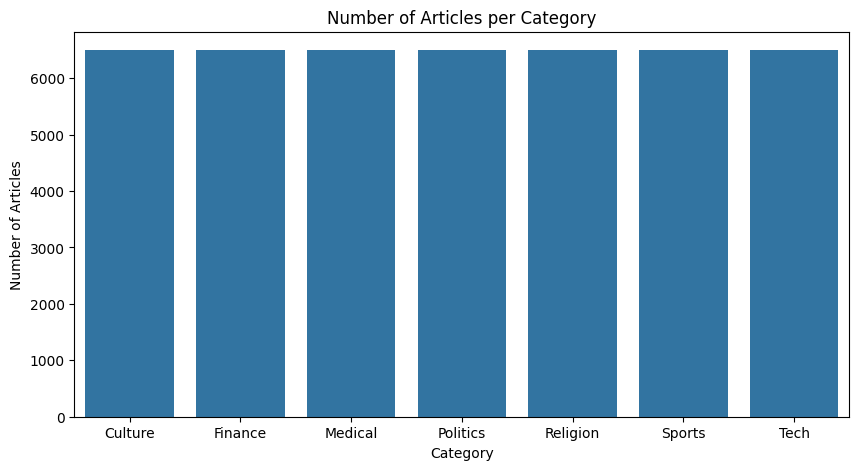

label
Culture     6500
Finance     6500
Medical     6500
Politics    6500
Religion    6500
Sports      6500
Tech        6500
Name: count, dtype: int64


In [24]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="label")
plt.title("Number of Articles per Category")
plt.xlabel("Category")
plt.ylabel("Number of Articles")
plt.show()

print(df["label"].value_counts())

In [25]:
df["text_length"] = df["text"].str.split().str.len()
print(df["text_length"].describe())

count    45500.000000
mean       369.238813
std        342.143936
min          2.000000
25%        143.000000
50%        258.000000
75%        476.000000
max       5786.000000
Name: text_length, dtype: float64


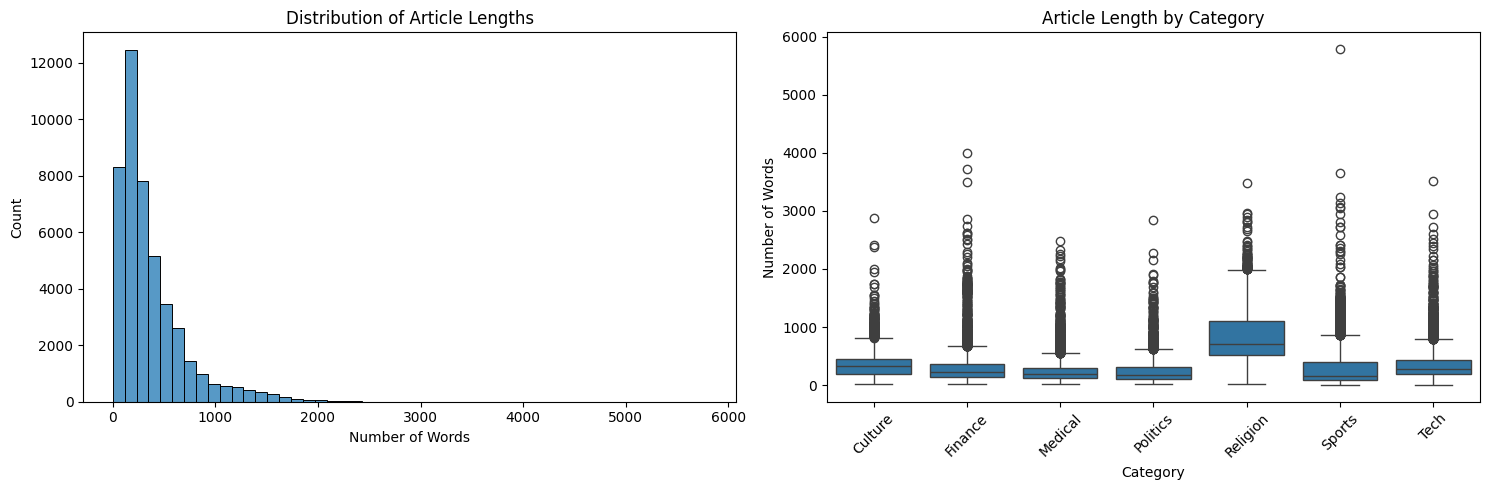

                mean  median  min   max
label                                  
Culture   348.219538   322.0   21  2871
Finance   296.175692   223.0   11  3999
Medical   246.736462   193.0   21  2482
Politics  237.737077   174.0   24  2849
Religion  809.917231   704.0   20  3474
Sports    295.247231   160.0    2  5786
Tech      350.638462   285.0    7  3523


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=df, x="text_length", bins=50, ax=axes[0])
axes[0].set_title("Distribution of Article Lengths")
axes[0].set_xlabel("Number of Words")

sns.boxplot(data=df, x="label", y="text_length", ax=axes[1])
axes[1].set_title("Article Length by Category")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Number of Words")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print(df.groupby("label")["text_length"].agg(["mean", "median", "min", "max"]))

In [27]:
print(df[df["text_length"] < 20]["label"].value_counts())

label
Finance    38
Tech        2
Sports      1
Name: count, dtype: int64


## 4. Data cleaning

### 4.1 Remove duplicates
Done **before** splitting so an identical article can never appear in both train and test.

In [28]:
before = len(df)
df = df.drop_duplicates(subset=["text", "label"]).reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows. Remaining: {len(df)}")

Removed 15 duplicate rows. Remaining: 45485


### 4.2 Arabic text cleaning

The original text stays in `df["text"]`. Every step below updates `df["clean_text"]`. The patterns are written with `re.compile(...)` so the code behaves the same on every pandas version.

1. hidden Unicode direction characters
2. emails
3. URLs (also the ones written with spaces, e.g. `www. sibf.com`)
4. HTML entities
5. HTML tags
6. diacritics (tashkeel)
7. tatweel (ـ)
8. normalize alef: أ إ آ ٱ → ا
9. normalize alef maqsura: ى → ي
10. normalize ta marbuta: ة → ه
11. digits (Western and Arabic-Indic)
12. Latin letters
13. punctuation and other symbols
14. extra whitespace
15. stopwords (the list goes through the same normalization as the text, otherwise it would not match)
16. one-letter tokens
17. stemming (Snowball Arabic light stemmer)
18. drop articles that became empty

All steps are fixed rules (nothing is learned from the data), so applying them before the split does not leak information from the test set.

In [29]:
df["clean_text"] = df["text"]

In [30]:
HIDDEN_CHARS = re.compile(r"[\u200b-\u200f\u202a-\u202e\u2066-\u2069]")
df["clean_text"] = df["clean_text"].str.replace(HIDDEN_CHARS, "", regex=True)

In [31]:
EMAIL = re.compile(r"\b[A-Za-z0-9._%+-]+\s*@\s*[A-Za-z0-9.-]+\s*\.\s*[A-Za-z]{2,}\b")
df["clean_text"] = df["clean_text"].str.replace(EMAIL, " ", regex=True)

In [32]:
URL = re.compile(
    r"https?:\s*/\s*/\s*"
    r"|\b(?:https?://\s*)?(?:www\s*\.\s*)?(?:[a-z0-9-]+\s*\.\s*)+[a-z]{2,}(?:\s*/[^\s]*)?",
    re.IGNORECASE)
df["clean_text"] = df["clean_text"].str.replace(URL, " ", regex=True)

In [33]:
df["clean_text"] = df["clean_text"].map(html.unescape)

In [34]:
HTML_TAG = re.compile(r"<[^>]+>")
df["clean_text"] = df["clean_text"].str.replace(HTML_TAG, " ", regex=True)

In [35]:
DIACRITICS = re.compile(r"[\u0610-\u061A\u064B-\u065F\u0670\u06D6-\u06ED]")
df["clean_text"] = df["clean_text"].str.replace(DIACRITICS, "", regex=True)

In [36]:
df["clean_text"] = df["clean_text"].str.replace("\u0640", "", regex=False)

In [37]:
ALEF_VARIANTS = re.compile("[أإآٱ]")
df["clean_text"] = df["clean_text"].str.replace(ALEF_VARIANTS, "ا", regex=True)

In [38]:
df["clean_text"] = df["clean_text"].str.replace("ى", "ي", regex=False)

In [39]:
df["clean_text"] = df["clean_text"].str.replace("ة", "ه", regex=False)

In [40]:
DIGITS = re.compile(r"[0-9\u0660-\u0669\u06F0-\u06F9]")
df["clean_text"] = df["clean_text"].str.replace(DIGITS, " ", regex=True)

In [41]:
LATIN = re.compile(r"[A-Za-z]")
df["clean_text"] = df["clean_text"].str.replace(LATIN, " ", regex=True)

In [42]:
NON_ARABIC = re.compile(r"[^\u0621-\u064A\s]")
df["clean_text"] = df["clean_text"].str.replace(NON_ARABIC, " ", regex=True)

In [43]:
WHITESPACE = re.compile(r"\s+")
df["clean_text"] = df["clean_text"].str.replace(WHITESPACE, " ", regex=True).str.strip()

In [44]:
nltk.download("stopwords", quiet=True)

stop = pd.Series(list(stopwords.words("arabic")))
stop = (stop.str.replace(DIACRITICS, "", regex=True)
            .str.replace("\u0640", "", regex=False)
            .str.replace(ALEF_VARIANTS, "ا", regex=True)
            .str.replace("ى", "ي", regex=False)
            .str.replace("ة", "ه", regex=False))
STOPWORDS = set(stop)
print("Number of stopwords:", len(STOPWORDS))

def remove_stopwords(text):
    return " ".join(word for word in text.split() if word not in STOPWORDS)

df["clean_text"] = df["clean_text"].apply(remove_stopwords)

Number of stopwords: 624


In [45]:
def remove_single_letters(text):
    return " ".join(word for word in text.split() if len(word) > 1)

df["clean_text"] = df["clean_text"].apply(remove_single_letters)

In [46]:
stemmer = SnowballStemmer("arabic")

@lru_cache(maxsize=None)
def stem_word(word):
    return stemmer.stem(word)

def stem_text(text):
    return " ".join(stem_word(word) for word in text.split())

df["clean_text"] = df["clean_text"].apply(stem_text)

In [47]:
print("Articles empty after cleaning:", (df["clean_text"] == "").sum())
df = df[df["clean_text"] != ""].reset_index(drop=True)
print("Final dataset size:", len(df))

print("\nBEFORE:", df.loc[0, "text"][:300])
print()
print("AFTER :", df.loc[0, "clean_text"][:300])

Articles empty after cleaning: 0
Final dataset size: 45485

BEFORE: الشارقة - محمد ولد محمد سالمعرضت مساء أمس الأول على خشبة مسرح قصر الثقافة في الشارقة المسرحية السعودية "بعيداً عن السيطرة" لفرقة مسرح الطائف، من تأليف فهد ردة الحارثي، وإخراج سامي صالح الزهراني، وذلك في رابعة ليالي الدورة الأولى من مهرجان الشارقة للمسرح الخليجي .تبدأ المسرحية بثلاثة أشخاص يجلسون في 

AFTER : شارقه محمد ولد محمد سالمعرض اول خشب مسرح قصر ثقافه شارقه مسرحيه سعوديه عيد سيطره لفرق مسرح طايف تاليف فهد رده حارث واخراج سام صالح زهران وذل رابع ليال دوره اول مهرج شارقه مسرح خليج تبد مسرحيه ثلاث اشخاص يجلس قاع مكتب ينهم منهم قراءه شغف يبدا حوار نكتشف انهم كانو يقرا روا استاذ كاتب مبدع مات وتر روا 


## 5. Stratified train / validation / test split (70 / 15 / 15)

In [48]:
X = df["clean_text"]
y = df["label"]


X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)


X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print(f"Train: {len(X_train)}   Validation: {len(X_val)}   Test: {len(X_test)}")

proportions = pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "val":   y_val.value_counts(normalize=True),
    "test":  y_test.value_counts(normalize=True),
}).round(4)
print("\nClass proportions (should be almost identical):")
print(proportions)

Train: 31839   Validation: 6823   Test: 6823

Class proportions (should be almost identical):
           train     val    test
label                           
Culture   0.1428  0.1428  0.1428
Finance   0.1429  0.1429  0.1429
Medical   0.1429  0.1429  0.1429
Politics  0.1429  0.1429  0.1429
Religion  0.1427  0.1428  0.1428
Sports    0.1429  0.1429  0.1429
Tech      0.1429  0.1429  0.1429


## 6. Feature extraction: TF-IDF

Settings: unigrams + bigrams, vocabulary capped at 50,000 terms, terms must appear in at least 3 documents, sublinear TF scaling.

The vectorizer is never fitted on data it will be evaluated on:
- inside the cross-validation, it is **re-fitted in every fold on that fold's training part only**;
- for the validation check and the final model, it is fitted on the whole training set (70%), and the validation / test sets are only transformed.

In [49]:
MAX_FEATURES = 50_000

def make_vectorizer():
    return TfidfVectorizer(
        max_features=MAX_FEATURES,
        ngram_range=(1, 2),
        min_df=3,
        sublinear_tf=True,
    )

print(make_vectorizer())

TfidfVectorizer(max_features=50000, min_df=3, ngram_range=(1, 2),
                sublinear_tf=True)


## 7. Hyperparameter tuning with stratified K-fold cross-validation

For each model we tune the regularization strength `C` (smaller `C` = stronger regularization) with **5-fold stratified cross-validation on the training set (the 70% part)**.

How it works: the training set is cut into 5 parts. Each part is used once as a small "validation" part while the other 4 parts are used for training. So every `C` gets 5 scores, and we pick the `C` with the best **average macro-F1**. The std tells us how stable it is.

The 15% validation set is **not** used to pick `C`

In [50]:
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

C_values_lr  = [0.1, 1, 10, 100]
C_values_svm = [0.01, 0.1, 1, 10]


folds = list(range(1, N_SPLITS + 1))
lr_scores  = pd.DataFrame(index=folds, columns=C_values_lr,  dtype=float)
svm_scores = pd.DataFrame(index=folds, columns=C_values_svm, dtype=float)

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), start=1):

    X_fold_train, y_fold_train = X_train.iloc[train_idx], y_train.iloc[train_idx]
    X_fold_val,   y_fold_val   = X_train.iloc[val_idx],   y_train.iloc[val_idx]

    # TF-IDF is fitted on the fold's training part only
    fold_vectorizer = make_vectorizer()
    X_fold_train_tfidf = fold_vectorizer.fit_transform(X_fold_train)
    X_fold_val_tfidf   = fold_vectorizer.transform(X_fold_val)

    # Logistic Regression with every C
    for C in C_values_lr:
        model = LogisticRegression(C=C, max_iter=1000, random_state=SEED)
        model.fit(X_fold_train_tfidf, y_fold_train)
        predictions = model.predict(X_fold_val_tfidf)
        lr_scores.loc[fold, C] = f1_score(y_fold_val, predictions, average="macro")

    # Linear SVM with every C
    for C in C_values_svm:
        model = LinearSVC(C=C, max_iter=5000, random_state=SEED)
        model.fit(X_fold_train_tfidf, y_fold_train)
        predictions = model.predict(X_fold_val_tfidf)
        svm_scores.loc[fold, C] = f1_score(y_fold_val, predictions, average="macro")

    print(f"Fold {fold}/{N_SPLITS} done")

Fold 1/5 done
Fold 2/5 done
Fold 3/5 done
Fold 4/5 done
Fold 5/5 done


In [51]:
print("Logistic Regression: macro-F1 in each fold (rows) for each C (columns)")
print(lr_scores.round(4))
print("\nLinear SVM: macro-F1 in each fold (rows) for each C (columns)")
print(svm_scores.round(4))

lr_mean,  lr_std  = lr_scores.mean(),  lr_scores.std()
svm_mean, svm_std = svm_scores.mean(), svm_scores.std()

best_C_lr  = lr_mean.idxmax()
best_C_svm = svm_mean.idxmax()

print("\nAverage macro-F1 per C")
print("Logistic Regression:", lr_mean.round(4).to_dict())
print("Linear SVM         :", svm_mean.round(4).to_dict())
print(f"\nBest C  ->  Logistic Regression: {best_C_lr}   |   Linear SVM: {best_C_svm}")

Logistic Regression: macro-F1 in each fold (rows) for each C (columns)
    0.1     1.0     10.0    100.0
1  0.9684  0.9758  0.9797  0.9794
2  0.9681  0.9774  0.9794  0.9785
3  0.9693  0.9788  0.9807  0.9821
4  0.9679  0.9772  0.9816  0.9834
5  0.9656  0.9757  0.9780  0.9787

Linear SVM: macro-F1 in each fold (rows) for each C (columns)
    0.01    0.10    1.00    10.00
1  0.9690  0.9759  0.9799  0.9799
2  0.9679  0.9771  0.9805  0.9804
3  0.9690  0.9794  0.9825  0.9818
4  0.9687  0.9775  0.9823  0.9829
5  0.9667  0.9757  0.9799  0.9790

Average macro-F1 per C
Logistic Regression: {0.1: 0.9679, 1.0: 0.977, 10.0: 0.9799, 100.0: 0.9804}
Linear SVM         : {0.01: 0.9683, 0.1: 0.9771, 1.0: 0.981, 10.0: 0.9808}

Best C  ->  Logistic Regression: 100.0   |   Linear SVM: 1.0


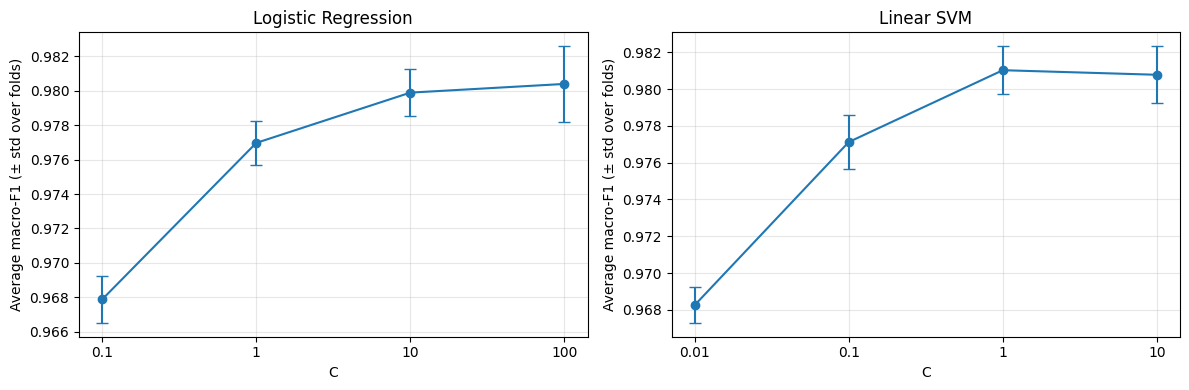

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].errorbar([str(c) for c in C_values_lr], lr_mean, yerr=lr_std, marker="o", capsize=4)
axes[0].set_title("Logistic Regression")

axes[1].errorbar([str(c) for c in C_values_svm], svm_mean, yerr=svm_std, marker="o", capsize=4)
axes[1].set_title("Linear SVM")

for ax in axes:
    ax.set_xlabel("C")
    ax.set_ylabel("Average macro-F1 (± std over folds)")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 7.1 Training the final models and checking them on the validation set

Now that `C` is chosen, TF-IDF is fitted on the **whole training set** and each model is trained once with its best `C`. We score them on the validation set as an independent check. `C` is **not** changed here.

In [53]:
vectorizer = make_vectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf   = vectorizer.transform(X_val)
print("Vocabulary size:", len(vectorizer.vocabulary_))


lr_model = LogisticRegression(C=best_C_lr, max_iter=1000, random_state=SEED)
lr_model.fit(X_train_tfidf, y_train)
lr_val_pred = lr_model.predict(X_val_tfidf)


svm_model = LinearSVC(C=best_C_svm, max_iter=5000, random_state=SEED)
svm_model.fit(X_train_tfidf, y_train)
svm_val_pred = svm_model.predict(X_val_tfidf)

print("\nValidation results")
print(f"Logistic Regression (C={best_C_lr}): accuracy={accuracy_score(y_val, lr_val_pred):.4f}   macro-F1={f1_score(y_val, lr_val_pred, average='macro'):.4f}")
print(f"Linear SVM          (C={best_C_svm}): accuracy={accuracy_score(y_val, svm_val_pred):.4f}   macro-F1={f1_score(y_val, svm_val_pred, average='macro'):.4f}")

Vocabulary size: 50000

Validation results
Logistic Regression (C=100.0): accuracy=0.9829   macro-F1=0.9828
Linear SVM          (C=1.0): accuracy=0.9829   macro-F1=0.9828


## 8. Final evaluation on the test set (run once)

The two models are already trained (on the training set, with the best `C`). We only transform the test set and predict, a single time.

In [54]:
X_test_tfidf = vectorizer.transform(X_test)

lr_test_pred  = lr_model.predict(X_test_tfidf)
svm_test_pred = svm_model.predict(X_test_tfidf)

class_names = sorted(y.unique())

print("=" * 70)
print("LOGISTIC REGRESSION")
print("=" * 70)
print(f"Test accuracy: {accuracy_score(y_test, lr_test_pred):.4f}\n")
print(classification_report(y_test, lr_test_pred, digits=4))

print("=" * 70)
print("LINEAR SVM")
print("=" * 70)
print(f"Test accuracy: {accuracy_score(y_test, svm_test_pred):.4f}\n")
print(classification_report(y_test, svm_test_pred, digits=4))

LOGISTIC REGRESSION
Test accuracy: 0.9823

              precision    recall  f1-score   support

     Culture     0.9722    0.9682    0.9702       974
     Finance     0.9846    0.9867    0.9857       975
     Medical     0.9877    0.9867    0.9872       975
    Politics     0.9877    0.9877    0.9877       975
    Religion     0.9653    0.9723    0.9688       974
      Sports     0.9979    0.9938    0.9959       975
        Tech     0.9805    0.9805    0.9805       975

    accuracy                         0.9823      6823
   macro avg     0.9823    0.9823    0.9823      6823
weighted avg     0.9823    0.9823    0.9823      6823

LINEAR SVM
Test accuracy: 0.9829

              precision    recall  f1-score   support

     Culture     0.9742    0.9702    0.9722       974
     Finance     0.9887    0.9856    0.9872       975
     Medical     0.9877    0.9846    0.9861       975
    Politics     0.9837    0.9897    0.9867       975
    Religion     0.9682    0.9702    0.9692       974
 

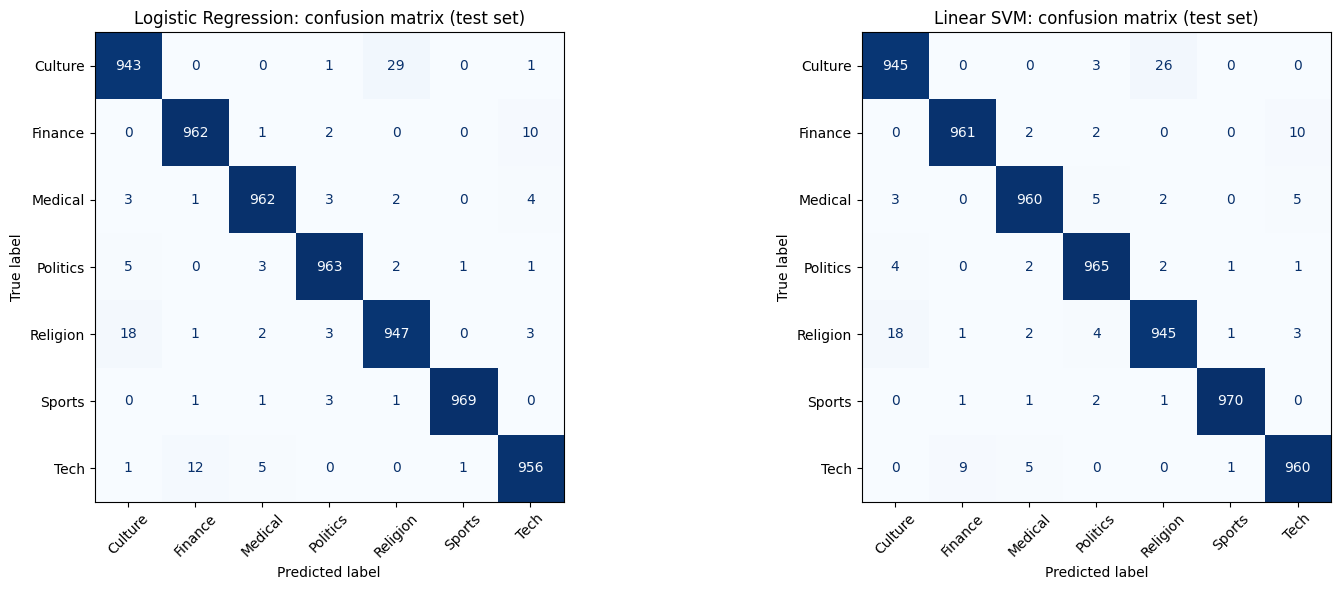

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test, lr_test_pred, labels=class_names, ax=axes[0],
    cmap="Blues", xticks_rotation=45, colorbar=False)
axes[0].set_title("Logistic Regression: confusion matrix (test set)")

ConfusionMatrixDisplay.from_predictions(
    y_test, svm_test_pred, labels=class_names, ax=axes[1],
    cmap="Blues", xticks_rotation=45, colorbar=False)
axes[1].set_title("Linear SVM: confusion matrix (test set)")

plt.tight_layout()
plt.show()

## 9. Summary

In [56]:
summary = pd.DataFrame(
    {
        "Logistic Regression": [
            best_C_lr,
            lr_mean[best_C_lr],
            f1_score(y_val,  lr_val_pred,  average="macro"),
            accuracy_score(y_test, lr_test_pred),
            f1_score(y_test, lr_test_pred, average="macro"),
        ],
        "Linear SVM": [
            best_C_svm,
            svm_mean[best_C_svm],
            f1_score(y_val,  svm_val_pred,  average="macro"),
            accuracy_score(y_test, svm_test_pred),
            f1_score(y_test, svm_test_pred, average="macro"),
        ],
    },
    index=["Best C", "CV macro-F1 (average)", "Validation macro-F1", "Test accuracy", "Test macro-F1"],
)

print("Vocabulary size:", len(vectorizer.vocabulary_))
summary.round(4)

Vocabulary size: 50000


,Logistic Regression,Linear SVM
Best C,100.0000,1.0000
CV macro-F1 (average),0.9804,0.9810
Validation macro-F1,0.9828,0.9828
Test accuracy,0.9823,0.9829
Test macro-F1,0.9823,0.9828
